# RISE（Shapley 版）：哪些区域把这张图推向重症一侧

参照取同一张图的高斯模糊（去掉病灶、血管等局部结构，保留颜色、亮度、视野形状）。只在视野内模糊，视野外的黑边不混进来，视野外参照 = 原图。显著图把 `s0 − s_ref`（原图得分 − 参照得分）分到各区域：

- 被遮区域填参照图（原版填 0，即标准化的均值色）；
- 每张遮罩的保留概率 q 各自取自 U(0, 1)（原版固定 p）；按 Owen 的公式，这样得到的是 Shapley 值，总和 = `s0 − s_ref`；
- 遮罩按 batch 生成、随算随加，内存不随遮罩数增长。

红 = 该区域相对参照把得分推高，蓝 = 推低，0 = 没有作用。实现见 `fmspace/rise.py` 的 `rise_shapley`。

先运行初始化格；其余各格只依赖它。每张图保存 `results/rise/<model>/<设定>/<image_id>.npz`：`sal`（显著图 `[K, H, W]`）、`s0`（原图得分）、`s_ref`（参照得分）。

In [1]:
import numpy as np
import pandas as pd
import torch
from PIL import Image

from fmspace.analysis import l2, pc_scorer, pca, rho
from fmspace.data import load_metadata
from fmspace.extract import load_features
from fmspace.models import load_model
from fmspace.paths import DATA_DIR, FEATURE_DIR, FIGURE_DIR, RISE_DIR
from fmspace.plots import saliency_figure
from fmspace.rise import field_of_view, fov_blur, rise_shapley

MODEL = "medsiglip"
COMPONENTS = {1: "eye_dr_level", 2: "eye"}  # 主成分 → 定方向用的标签
N_MASKS, GRID, SEED = 16000, 14, 0
SIGMAS = [4, 8, 16, 32]  # 模糊检查的候选（模型输入的像素）
SIGMA = 16  # 参照的模糊强度，看完模糊检查再定
PER_GRADE = 1
QUALITY = {"overall_quality": False, "artifact": True, "clarity": False, "field_definition": False}  # 排序列 → 是否升序

metadata = load_metadata(DATA_DIR).set_index("image_id", drop=False)
X = l2(load_features(FEATURE_DIR / f"{MODEL}.npz", metadata["image_id"]))
fitted = pca(X)
pcs = fitted.transform(X)[:, np.array(list(COMPONENTS)) - 1]
signs = np.array([np.sign(rho(pcs[:, j], metadata[label].rank())) for j, label in enumerate(COMPONENTS.values())])
scores = pd.DataFrame(pcs * signs, index=metadata.index, columns=[f"PC{k}" for k in COMPONENTS])
ranked = scores.join(metadata[["eye", "eye_dr_level", *QUALITY]]).sort_values(list(QUALITY), ascending=list(QUALITY.values()))
selected = ranked.groupby("eye_dr_level").head(PER_GRADE)

preprocess, forward = load_model(MODEL, "cuda")
model = pc_scorer(torch.autocast("cuda", dtype=torch.float16)(forward), fitted, list(COMPONENTS), signs)
OUT = RISE_DIR / MODEL / f"shapley_grid{GRID}_n{N_MASKS}_blur{SIGMA}"
OUT.mkdir(parents=True, exist_ok=True)

/home/tsakailab/workspace/WZX/fm_space/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 448/448 [00:00<00:00, 8354.07it/s]
[transformers] SiglipVisionModel LOAD REPORT from: google/medsiglip-448
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...26}.self_attn.out_proj.weight | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.self_attn.k_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.self_attn.q_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.mlp.fc1.weight            | UNEXPECTED |  | 
text_model.encoder.l

## 模糊检查

全部图像在各模糊强度下的得分（`sigma` = 0 为原图）。参照合适的条件：模糊后得分与标签的相关接近 0，各 DR 等级的 PC1 均值靠拢。取满足条件的最小 σ 填进初始化格的 `SIGMA`。

In [2]:
rows = []
with torch.inference_mode():
    for i in range(0, len(metadata), 32):
        ids = metadata.index[i : i + 32]
        images = [Image.open(metadata["path"][j]).convert("RGB") for j in ids]
        x = preprocess(images)
        fov = torch.stack([field_of_view(im, x.shape[2:]) for im in images]).to(x)
        for sigma in [0, *SIGMAS]:
            s = model(fov_blur(x, fov, sigma) if sigma else x).numpy()
            rows.append(pd.DataFrame(s, index=ids, columns=scores.columns).assign(sigma=sigma))
blurred = pd.concat(rows).join(metadata[list(COMPONENTS.values())])
blurred.to_csv(RISE_DIR / MODEL / "blur_check.csv")

correlations = pd.DataFrame({sigma: {f"rho {pc}": rho(d[pc], d[label].rank()) for pc, label in zip(scores.columns, COMPONENTS.values())}
                             for sigma, d in blurred.groupby("sigma")}).T
correlations.join(blurred.pivot_table(index="sigma", columns="eye_dr_level", values="PC1").add_prefix("PC1 DR")).round(3)

,rho PC1,rho PC2,PC1 DR0,PC1 DR1,PC1 DR2,PC1 DR3,PC1 DR4
0,0.786,0.797,-0.286,-0.131,0.286,0.379,0.320
4,0.705,0.703,-0.240,-0.220,-0.073,0.044,0.035
8,0.610,0.466,-0.210,-0.176,-0.136,-0.084,-0.056
16,0.590,0.275,-0.321,-0.284,-0.265,-0.241,-0.211
32,0.573,0.022,-0.346,-0.307,-0.300,-0.289,-0.281


## 跑 RISE

每个 DR 等级取画质最好的 `PER_GRADE` 张：整体画质好、无伪影、清晰度与视野定义最高（`QUALITY` 依次排序）。已有结果的图跳过。

In [4]:
for image_id in selected.index:
    if (OUT / f"{image_id}.npz").exists():
        continue
    image = Image.open(metadata["path"][image_id]).convert("RGB")
    x = preprocess([image])
    baseline = fov_blur(x, field_of_view(image, x.shape[2:])[None].to(x), SIGMA)
    sal = rise_shapley(model, x, baseline, N=N_MASKS, s=GRID, seed=SEED)
    with torch.inference_mode():
        s0, s_ref = model(x)[0], model(baseline)[0]
    np.savez(OUT / f"{image_id}.npz", sal=sal.numpy(), s0=s0.numpy(), s_ref=s_ref.numpy())

100%|██████████| 500/500 [03:45<00:00,  2.22it/s]


## 汇总

每张图、每个主成分一行：`total` 是显著图总和（按格子面积换算），应等于 `s0 − s_ref`，即 `ratio` ≈ 1。距图像边缘一格以内的像素会被少算（遮罩的性质，原版 RISE 相同），视野贴边时 `ratio` 略小于 1。

In [5]:
rows = []
for image_id in selected.index:
    d = np.load(OUT / f"{image_id}.npz")
    h, w = d["sal"].shape[1:]
    cell = ((GRID + 1) * np.ceil(h / GRID) / GRID) * ((GRID + 1) * np.ceil(w / GRID) / GRID)
    for j, pc in enumerate(scores.columns):
        s0, s_ref, total = d["s0"][j], d["s_ref"][j], d["sal"][j].sum() / cell
        rows.append({"image_id": image_id, "dr": metadata["eye_dr_level"][image_id], "eye": metadata["eye"][image_id], "pc": pc,
                     "s0": s0, "s_ref": s_ref, "total": total, "ratio": total / (s0 - s_ref)})
summary = pd.DataFrame(rows).sort_values(["pc", "dr", "s0"])
summary.to_csv(OUT / "summary.csv", index=False)
summary

,image_id,dr,eye,pc,s0,s_ref,total,ratio
0,5_l1,0,L,PC1,-0.254129,-0.346491,0.090374,0.978485
6,20_r2,1,R,PC1,0.031876,-0.243949,0.272252,0.987049
8,26_l2,2,L,PC1,0.334904,-0.257927,0.630765,1.063988
4,12_r2,3,R,PC1,0.468380,-0.340604,0.842895,1.041918
2,12_l2,4,L,PC1,0.442682,-0.305499,0.786194,1.050808
1,5_l1,0,L,PC2,-0.044631,0.029372,-0.086147,1.164096
7,20_r2,1,R,PC2,0.428921,0.130989,0.340366,1.142428
9,26_l2,2,L,PC2,-0.226800,0.010556,-0.234139,0.986447
5,12_r2,3,R,PC2,0.176064,0.035727,0.148497,1.058140
3,12_l2,4,L,PC2,-0.281886,0.033085,-0.306449,0.972946


## 画图

按 DR 等级、PC1 得分排序；每列共用色标。行标签：各主成分的参照得分 → 原图得分。

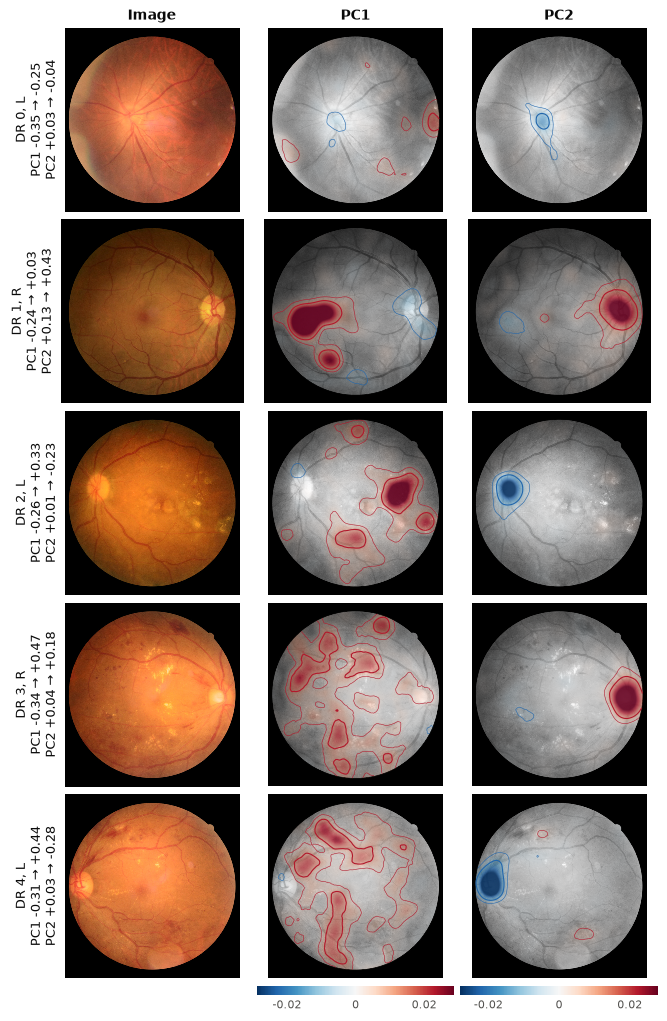

In [2]:
done = selected.sort_values(["eye_dr_level", "PC1"])
maps = [np.load(OUT / f"{i}.npz") for i in done.index]
images = [Image.open(metadata["path"][i]).convert("RGB") for i in done.index]
labels = ["\n".join([f"DR {r.eye_dr_level}, {r.eye}", *(f"{c} {m['s_ref'][j]:+.2f} → {m['s0'][j]:+.2f}" for j, c in enumerate(scores.columns))])
          for r, m in zip(done.itertuples(), maps)]
fig = saliency_figure(images, [m["sal"] for m in maps], labels, list(scores.columns))
fig.savefig(FIGURE_DIR / f"rise_{MODEL}_{OUT.name}.png", dpi=600, bbox_inches="tight")